# LAB 10 — Tokenizer, offsets và answer-span alignment

W10.pdf mục 10, 11, 13, 15, 16. Notebook hiển thị tokenizer inputs/offsets; character-to-token alignment và answer-window coverage để sinh viên tự triển khai.

In [1]:
from pathlib import Path
import subprocess, sys
roots = [Path.cwd(), Path.cwd()/"Lab10", Path("/content/NLP/Lab10"), Path("/content/drive/MyDrive/NLP/Lab10")]
LAB_DIR = next((p.resolve() for p in roots if (p/"qa_model.py").is_file()), None)
if LAB_DIR is None and Path("/content").exists():
    repo = Path("/content/NLP")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "origin", "main"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/NguyenDucThang-tb/NLP.git", str(repo)], check=True)
    LAB_DIR = repo/"Lab10"
if LAB_DIR is None or not (LAB_DIR/"qa_model.py").is_file():
    raise FileNotFoundError("Lab10/qa_model.py không có trong runtime. Push Lab10 lên GitHub rồi clone/pull repo.")
sys.path.insert(0, str(LAB_DIR))
print("LAB_DIR:", LAB_DIR)


LAB_DIR: /home/nguyenducthang/NLP/Lab10


## Cài đặt và dataset inspection

In [2]:
import importlib.util
from importlib.metadata import PackageNotFoundError, version
from packaging.requirements import Requirement
from packaging.version import Version

requirements = [Requirement(line.strip()) for line in (LAB_DIR / "requirements.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")]
missing_or_incompatible = []
for requirement in requirements:
    try:
        installed = Version(version(requirement.name))
    except PackageNotFoundError:
        missing_or_incompatible.append(str(requirement))
        continue
    if requirement.specifier and installed not in requirement.specifier:
        missing_or_incompatible.append(str(requirement))

if missing_or_incompatible:
    if importlib.util.find_spec("pip") is None:
        raise RuntimeError("pip is unavailable and dependencies are missing/incompatible: " + ", ".join(missing_or_incompatible))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(LAB_DIR / "requirements.txt")], check=True)
else:
    print("All requirements are already installed with compatible versions.")
if importlib.util.find_spec("torch") is None:
    raise RuntimeError("PyTorch is missing. Install a CPU/CUDA build appropriate for this runtime.")


All requirements are already installed with compatible versions.


In [3]:
prediction_text = (LAB_DIR / "prediction.md").read_text(encoding="utf-8")
if any(line.strip().upper().startswith("TODO:") for line in prediction_text.splitlines()):
    raise RuntimeError("Hoàn thành prediction.md trước khi mở output mẫu/câu trả lời của dataset.")
import pandas as pd
from IPython.display import display
from qa_model import (DATASET_ID, MODEL_ID, load_squad, build_tokenizer,
                      example_answer_is_in_context)

dataset = load_squad(DATASET_ID)
print(dataset)
print("split sizes:", {name: len(split) for name, split in dataset.items()})
sample = dataset["train"][0]
print("sample id/title:", sample["id"], sample["title"])
print("question:", sample["question"])
print("gold answers:", sample["answers"])
print("context preview:", sample["context"][:500])
print("annotated answer matches the context offset:", example_answer_is_in_context(sample))


DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})
split sizes: {'train': 87599, 'validation': 10570}
sample id/title: 5733be284776f41900661182 University_of_Notre_Dame
question: To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
gold answers: {'text': ['Saint Bernadette Soubirous'], 'answer_start': [515]}
context preview: Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of 

## QA tokenization — question/context, overflow và offsets

`sequence_id=0`: question; `sequence_id=1`: context; `None`: special token. Chưa tính answer token span.

In [4]:
tokenizer = None
encoded = None
try:
    tokenizer = build_tokenizer(MODEL_ID)
    encoded = tokenizer(sample["question"], sample["context"], truncation="only_second",
        max_length=384, stride=128, return_overflowing_tokens=True,
        return_offsets_mapping=True, padding=False)
    print("fast:", tokenizer.is_fast, "model inputs:", tokenizer.model_input_names)
    print("windows:", len(encoded["input_ids"]), "overflow mapping:", encoded["overflow_to_sample_mapping"])
    print("token_type_ids returned:", "token_type_ids" in encoded)
except OSError as error:
    print("NOT_RUN: pretrained tokenizer is not available offline:", str(error).splitlines()[0])


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

fast: True model inputs: ['input_ids', 'token_type_ids', 'attention_mask']
windows: 1 overflow mapping: [0]
token_type_ids returned: True


In [5]:
if encoded is None:
    print("NOT_RUN: token table requires the pretrained tokenizer.")
else:
    window_id = 0
    sequence_ids = encoded.sequence_ids(window_id)
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][window_id])
    offsets = encoded["offset_mapping"][window_id]
    attention = encoded["attention_mask"][window_id]
    type_ids = encoded.get("token_type_ids", [None] * len(encoded["input_ids"]))[window_id]
    table = pd.DataFrame([
        {"token_index": i, "token_id": encoded["input_ids"][window_id][i], "token": token,
         "sequence_id": sid, "segment": {None: "special", 0: "question", 1: "context"}[sid],
         "character_start": off[0], "character_end_exclusive": off[1],
         "attention_mask": attention[i],
         "token_type_id": type_ids[i] if type_ids is not None else "not provided"}
        for i, (token, sid, off) in enumerate(zip(tokens, sequence_ids, offsets))
    ])
    display(table)
    print("overflow_to_sample_mapping:", encoded["overflow_to_sample_mapping"])
    print("sequence_ids:", sequence_ids)
    print("answer start in original context:", sample["answers"]["answer_start"][0])
    print("answer text:", sample["answers"]["text"][0])


,token_index,token_id,token,sequence_id,segment,character_start,character_end_exclusive,attention_mask,token_type_id
0,0,101,[CLS],NaN,special,0,0,1,0
1,1,2000,to,0.0,question,0,2,1,0
2,2,3183,whom,0.0,question,3,7,1,0
3,3,2106,did,0.0,question,8,11,1,0
4,4,1996,the,0.0,question,12,15,1,0
...,...,...,...,...,...,...,...,...,...
171,171,6231,statue,1.0,context,680,686,1,1
172,172,1997,of,1.0,context,687,689,1,1
173,173,2984,mary,1.0,context,690,694,1,1
174,174,1012,.,1.0,context,694,695,1,1


overflow_to_sample_mapping: [0]
sequence_ids: [None, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, None, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, None]
answer start in original context: 515
answer text: Saint Bernadette Soubirous


## Padding và các special tokens

Phần này chỉ quan sát padding/special tokens. Offset `(0, 0)` và sequence id `None` không đại diện cho đoạn context.

In [6]:
if tokenizer is None:
    print("NOT_RUN: padded token table requires the pretrained tokenizer.")
else:
    padded = tokenizer(sample["question"], sample["context"], truncation="only_second",
                       max_length=64, padding="max_length", return_offsets_mapping=True)
    padded_ids = padded["input_ids"]
    padded_tokens = tokenizer.convert_ids_to_tokens(padded_ids)
    padded_offsets = padded["offset_mapping"]
    padded_mask = padded["attention_mask"]
    padded_table = pd.DataFrame([
        {"token_index": i, "token": token, "attention_mask": padded_mask[i],
         "is_padding": padded_mask[i] == 0,
         "offset_start": padded_offsets[i][0], "offset_end_exclusive": padded_offsets[i][1]}
        for i, token in enumerate(padded_tokens)
    ])
    display(padded_table.tail(20))


,token_index,token,attention_mask,is_padding,offset_start,offset_end_exclusive
44,44,immediately,1,False,128,139
45,45,in,1,False,140,142
46,46,front,1,False,143,148
47,47,of,1,False,149,151
48,48,the,1,False,152,155
49,49,main,1,False,156,160
50,50,building,1,False,161,169
51,51,and,1,False,170,173
52,52,facing,1,False,174,180
53,53,it,1,False,181,183


## Sliding-window visualization

Chart chỉ hiển thị context token range trên từng feature. Answer coverage chưa được tính; cần tự hoàn thiện `window_answer_coverage()` trước.

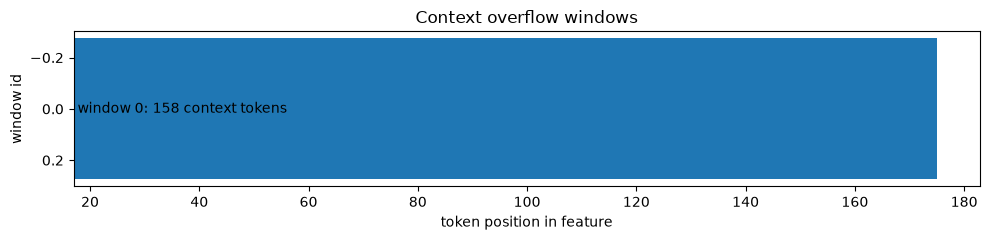

In [7]:
if encoded is None:
    print("NOT_RUN: sliding-window plot requires the pretrained tokenizer.")
else:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(10, max(2.5, 0.55 * len(encoded["input_ids"]))))
    for wi in range(len(encoded["input_ids"])):
        context_positions = [i for i, sid in enumerate(encoded.sequence_ids(wi)) if sid == 1]
        if context_positions:
            left, right = min(context_positions), max(context_positions) + 1
            ax.barh(wi, right - left, left=left, height=.55)
            ax.text(left, wi, f" window {wi}: {len(context_positions)} context tokens", va="center")
    ax.set(xlabel="token position in feature", ylabel="window id", title="Context overflow windows")
    ax.invert_yaxis(); fig.tight_layout(); plt.show()


## Student TODO — alignment cases

Tự hoàn thiện `character_to_token_span`, `prepare_train_features`, `prepare_validation_features`, `window_answer_coverage` trong `qa_model.py`. Kiểm tra: answer 1/nhiều token; start/end giữa token; answer trong/ngoài window; truncation; answer text lặp; nhiều sliding windows; mapping feature về đúng sample. Chỉ đánh dấu PASS sau khi tự điền expected token spans đã kiểm tra từ bảng tokenizer.

In [8]:
# Các trường hợp dưới đây là checklist để người học tự lập expected token indices.
# Không đặt expected spans tự động vì đây là phần alignment sinh viên phải tự kiểm chứng.
alignment_cases = [
    "one-token answer", "multi-token answer", "answer starts inside a token",
    "answer ends inside a token", "answer outside this window", "truncated answer",
    "answer fully inside a window", "repeated answer text", "multiple overflow windows",
    "special tokens", "question tokens", "padding tokens", "overflow-to-sample mapping",
]
print("NOT_RUN: implement alignment and write manually verified expected spans before enabling tests.")
for case in alignment_cases:
    print("-", case)


NOT_RUN: implement alignment and write manually verified expected spans before enabling tests.
- one-token answer
- multi-token answer
- answer starts inside a token
- answer ends inside a token
- answer outside this window
- truncated answer
- answer fully inside a window
- repeated answer text
- multiple overflow windows
- special tokens
- question tokens
- padding tokens
- overflow-to-sample mapping
